In [1]:
import tensorflow as tf
from tensorflow.keras import models, layers
import matplotlib.pyplot as plt

In [2]:
BATCH_SIZE = 32
IMAGE_SIZE = 640
CHANNELS=3
EPOCHS=15

In [3]:
input_shape = (640, 640, 3)

In [4]:
dataset = tf.keras.preprocessing.image_dataset_from_directory(
    r'/home/smartcity_sp7/EC_Classification/AUG',
    shuffle=True,
    image_size=(IMAGE_SIZE,IMAGE_SIZE),
    batch_size=BATCH_SIZE
)

Found 1074 files belonging to 3 classes.


In [5]:
class_names = dataset.class_names
class_names

['Dysplasia', 'Normal', 'SCC']

In [6]:
for image_batch, labels_batch in dataset.take(1):
    print(image_batch.shape)
    print(labels_batch.numpy())

(32, 640, 640, 3)
[0 1 1 1 2 0 2 0 2 0 2 1 2 0 2 2 0 1 1 1 2 2 1 0 0 0 0 2 1 0 1 2]


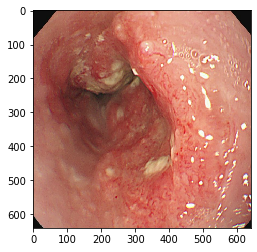

In [7]:
plt.imshow(image_batch[4].numpy().astype("uint8"))

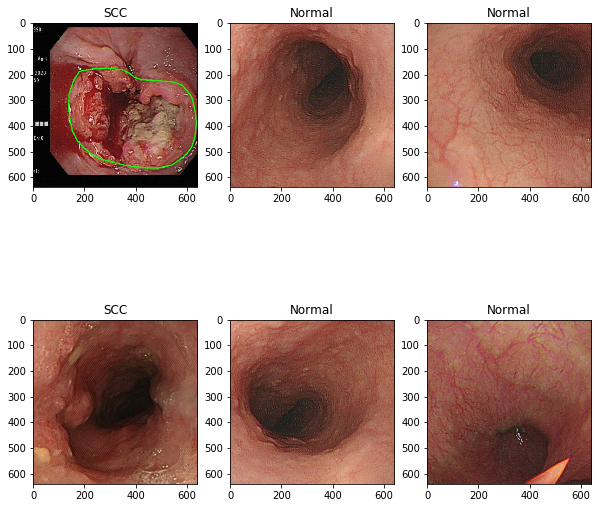

In [8]:
plt.figure(figsize=(10, 10))
for image_batch, labels_batch in dataset.take(1):
    for i in range (6):
        plt.subplot(2,3,i+1)
        plt.imshow(image_batch[i].numpy().astype("uint8"))
        plt.title(class_names[labels_batch[i]])

In [9]:
def get_dataset_partitions_tf(ds, train_split=0.8, val_split=0.05, test_split=0.15, shuffle=True, shuffle_size=10):
    assert (train_split + test_split + val_split) == 1
    ds_size = len(ds)
    if shuffle:
        ds = ds.shuffle(shuffle_size, seed=12)
    train_size = int(train_split * ds_size)
    val_size = int(val_split * ds_size)
    train_ds = ds.take(train_size)
    val_ds = ds.skip(train_size).take(val_size)
    test_ds = ds.skip(train_size).skip(val_size)
    return train_ds, val_ds, test_ds

In [10]:
train_ds, val_ds, test_ds = get_dataset_partitions_tf(dataset)

In [11]:
len(train_ds)

27

In [12]:
len(test_ds)

6

In [13]:
resize_and_rescale = tf.keras.Sequential([
  layers.experimental.preprocessing.Resizing(IMAGE_SIZE, IMAGE_SIZE),
  layers.experimental.preprocessing.Rescaling(1./255),
])

In [14]:
input_shape = (BATCH_SIZE, IMAGE_SIZE, IMAGE_SIZE, CHANNELS)
n_classes = 3

model = models.Sequential([
    resize_and_rescale,
    layers.Conv2D(32, kernel_size = (3,3), activation='relu', input_shape=[640,640,3]),
    layers.MaxPooling2D((2, 2)),
    layers.Conv2D(64,  kernel_size = (3,3), activation='relu'),
    layers.MaxPooling2D((2, 2)),
    layers.Conv2D(64, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),
    layers.Conv2D(64, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),
    layers.Flatten(),
    layers.Dense(64, activation='relu'),
    layers.Dense(n_classes, activation='softmax'),
])

model.build(input_shape=input_shape)

In [15]:
model.compile(
    optimizer='adam',
    loss=tf.keras.losses.SparseCategoricalCrossentropy(from_logits=False),
    metrics=['accuracy']
)

In [16]:
model.summary()

Model: "sequential_1"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 sequential (Sequential)     (32, 640, 640, 3)         0         
                                                                 
 conv2d (Conv2D)             (32, 638, 638, 32)        896       
                                                                 
 max_pooling2d (MaxPooling2D  (32, 319, 319, 32)       0         
 )                                                               
                                                                 
 conv2d_1 (Conv2D)           (32, 317, 317, 64)        18496     
                                                                 
 max_pooling2d_1 (MaxPooling  (32, 158, 158, 64)       0         
 2D)                                                             
                                                                 
 conv2d_2 (Conv2D)           (32, 156, 156, 64)       

In [17]:
model.fit(
    train_ds,
    verbose=1,
    epochs=10,
)

Epoch 1/10
27/27 [==============================] - 517s 19s/step - loss: 1.2185 - accuracy: 0.3738
Epoch 2/10
27/27 [==============================] - 496s 18s/step - loss: 0.9033 - accuracy: 0.5482
Epoch 3/10
27/27 [==============================] - 470s 17s/step - loss: 0.7459 - accuracy: 0.6812
Epoch 4/10
27/27 [==============================] - 505s 19s/step - loss: 0.5494 - accuracy: 0.7720
Epoch 5/10
27/27 [==============================] - 533s 20s/step - loss: 0.4462 - accuracy: 0.8241
Epoch 6/10
27/27 [==============================] - 485s 18s/step - loss: 0.3416 - accuracy: 0.8624
Epoch 7/10
27/27 [==============================] - 619s 23s/step - loss: 0.3311 - accuracy: 0.8692
Epoch 8/10
27/27 [==============================] - 590s 22s/step - loss: 0.2803 - accuracy: 0.8947
Epoch 9/10
27/27 [==============================] - 576s 21s/step - loss: 0.2144 - accuracy: 0.9141
Epoch 10/10
27/27 [==============================] - 602s 22s/step - loss: 0.1520 - accuracy: 0.9447

first image to predict
actual label: Normal
1/1 [==============================] - 5s 5s/step
predicted label: Normal


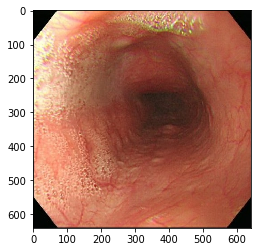

In [18]:
import numpy as np
for image_batch, labels_batch in test_ds.take(1):
    first_image = image_batch[1].numpy().astype('uint8')
    first_label = labels_batch[1].numpy()
    print("first image to predict")
    plt.imshow(first_image)
    print("actual label:",class_names[first_label])
    batch_prediction = model.predict(image_batch)
    print("predicted label:",class_names[np.argmax(batch_prediction[1])])

In [19]:
def predict(model, img):
    img_array = tf.keras.preprocessing.image.img_to_array(images[i].numpy())
    img_array = tf.expand_dims(img_array, 0)
    predictions = model.predict(img_array)
    predicted_class = class_names[np.argmax(predictions[0])]
    confidence = round(100 * (np.max(predictions[0])), 2)
    return predicted_class, confidence

1/1 [==============================] - 0s 285ms/step


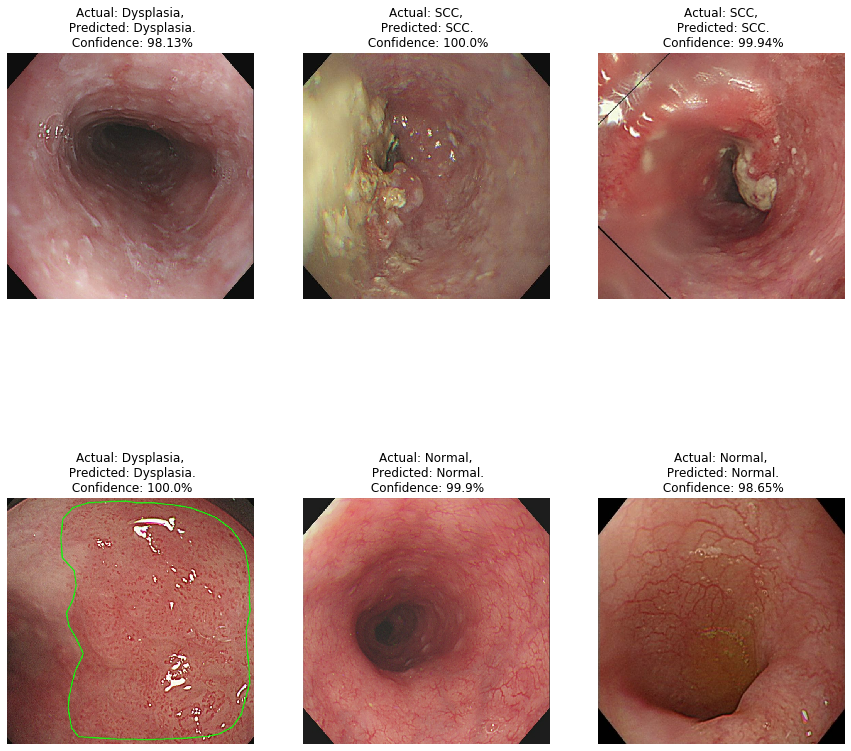

In [20]:
plt.figure(figsize=(15, 15))
for images, labels in test_ds.take(1):
    for i in range(6):
        ax = plt.subplot(2, 3, i + 1)
        plt.imshow(images[i].numpy().astype("uint8"))
        predicted_class, confidence = predict(model, images[i].numpy())
        actual_class = class_names[labels[i]]
        plt.title(f"Actual: {actual_class},\n Predicted: {predicted_class}.\n Confidence: {confidence}%")
        plt.axis("off")

In [21]:
import numpy as np
from sklearn.metrics import classification_report, confusion_matrix
import pandas as pd
y_pred = []
y_true = []
for images, labels in test_ds:
    predictions = model.predict(images)
    y_pred.extend(np.argmax(predictions, axis=1))
    y_true.extend(labels.numpy())
y_true = np.array(y_true)
y_pred = np.array(y_pred)

1/1 [==============================] - 5s 5s/step


In [22]:
report = classification_report(y_true, y_pred, target_names=class_names)
print("Classification Report:\n\n", report)

Classification Report:

               precision    recall  f1-score   support

   Dysplasia       0.96      0.90      0.93        73
      Normal       0.93      0.96      0.95        57
         SCC       0.90      0.94      0.92        48

    accuracy                           0.93       178
   macro avg       0.93      0.94      0.93       178
weighted avg       0.93      0.93      0.93       178



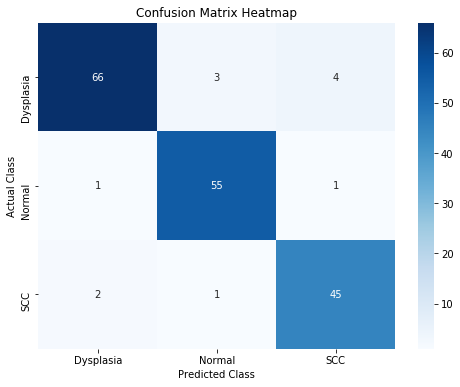

In [23]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
cm = confusion_matrix(y_true, y_pred)
cm_df = pd.DataFrame(cm, columns=class_names, index=class_names)
plt.figure(figsize=(8, 6))
sns.heatmap(cm_df, annot=True, fmt="d", cmap="Blues")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.title("Confusion Matrix Heatmap")
plt.show()

In [27]:
model.save_weights('/home/smartcity_sp7/EC_Classification/CNN-WLI weight')

In [26]:
model.save('/home/smartcity_sp7/EC_Classification/CNN-WLI')

INFO:tensorflow:Assets written to: /home/smartcity_sp7/EC_Classification/CNN-WLI/assets


INFO:tensorflow:Assets written to: /home/smartcity_sp7/EC_Classification/CNN-WLI/assets
